In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib

In [3]:
column_names = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety",
    "class"
]

df = pd.read_csv("/content/drive/MyDrive/car+evaluation/car.data", names=column_names)

df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [4]:
df.shape

(1728, 7)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [6]:
df.isnull().sum()

,0
buying,0
maint,0
doors,0
persons,0
lug_boot,0
safety,0
class,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
for column in df.columns:
    print(column)
    print(df[column].unique())
    print()

buying
['vhigh' 'high' 'med' 'low']

maint
['vhigh' 'high' 'med' 'low']

doors
['2' '3' '4' '5more']

persons
['2' '4' 'more']

lug_boot
['small' 'med' 'big']

safety
['low' 'med' 'high']

class
['unacc' 'acc' 'vgood' 'good']



In [10]:
df["class"].value_counts()


,count
class,
unacc,1210
acc,384
good,69
vgood,65


In [11]:
df["class"].value_counts(normalize=True) * 100

,proportion
class,
unacc,70.023148
acc,22.222222
good,3.993056
vgood,3.761574


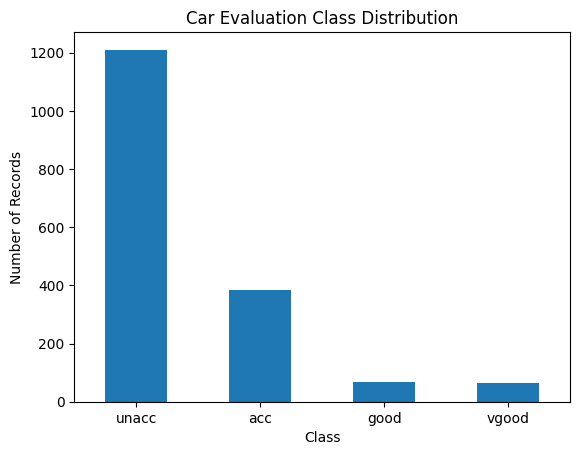

In [12]:
df["class"].value_counts().plot(kind="bar")

plt.title("Car Evaluation Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

In [13]:
X = df.drop("class", axis=1)
y = df["class"]

In [14]:
X.head()
y.head()

,class
0,unacc
1,unacc
2,unacc
3,unacc
4,unacc


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [16]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (1382, 6)
Testing features: (346, 6)
Training labels: (1382,)
Testing labels: (346,)


In [17]:
categorical_features = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety"
]

In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [19]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    )
}

In [20]:
results = []

trained_models = {}

for model_name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    trained_models[model_name] = pipeline

In [23]:
results_df.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.979769,0.982300,0.953319,0.967006
1,Decision Tree,0.973988,0.954533,0.941025,0.945033
0,Logistic Regression,0.901734,0.803379,0.775293,0.787257
3,K-Nearest Neighbors,0.893064,0.842194,0.653358,0.706890


In [24]:
display_results = results_df.copy()

for column in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]:
    display_results[column] = (
        display_results[column] * 100
    ).round(2)

display_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,90.17,80.34,77.53,78.73
1,Decision Tree,97.40,95.45,94.10,94.50
2,Random Forest,97.98,98.23,95.33,96.70
3,K-Nearest Neighbors,89.31,84.22,65.34,70.69


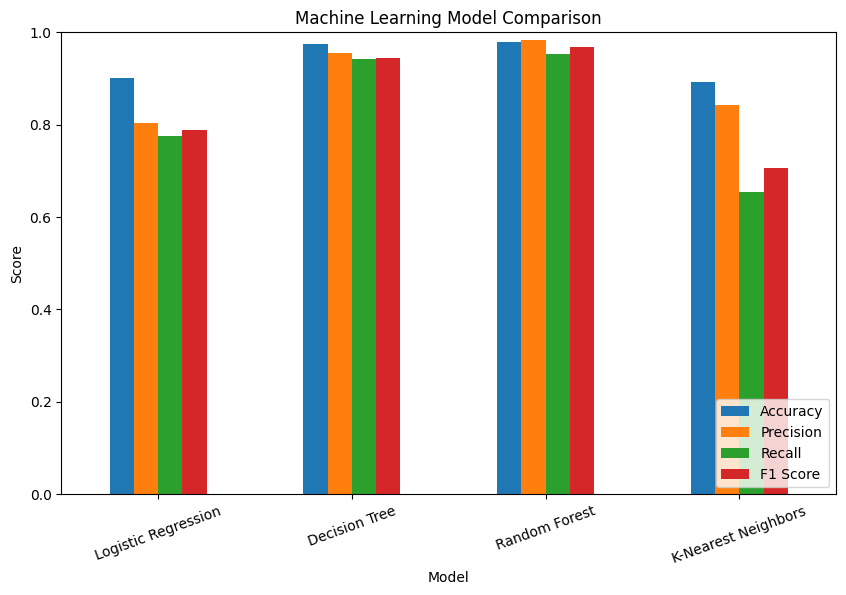

In [25]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.show()

In [26]:
best_row = results_df.loc[
    results_df["F1 Score"].idxmax()
]

best_row

,2
Model,Random Forest
Accuracy,0.979769
Precision,0.9823
Recall,0.953319
F1 Score,0.967006


In [27]:
best_model_name = best_row["Model"]

print("Best model:", best_model_name)

Best model: Random Forest


In [28]:
best_model = trained_models[best_model_name]

In [29]:
best_predictions = best_model.predict(X_test)

print(
    classification_report(
        y_test,
        best_predictions
    )
)

              precision    recall  f1-score   support

         acc       0.94      0.97      0.96        77
        good       1.00      0.93      0.96        14
       unacc       0.99      0.99      0.99       242
       vgood       1.00      0.92      0.96        13

    accuracy                           0.98       346
   macro avg       0.98      0.95      0.97       346
weighted avg       0.98      0.98      0.98       346



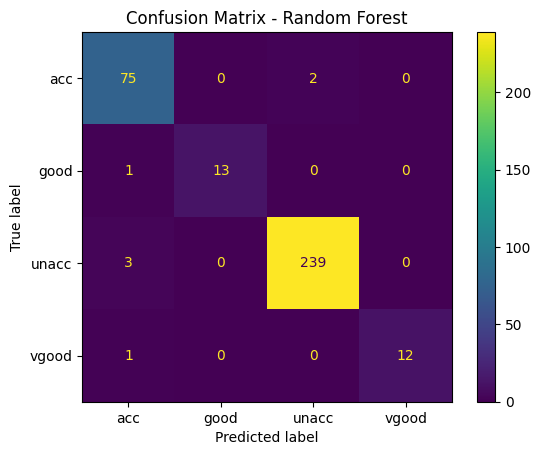

In [30]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=best_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

disp.plot()

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.show()

In [31]:
best_model.classes_

array(['acc', 'good', 'unacc', 'vgood'], dtype=object)

In [32]:
sample_car = pd.DataFrame([
    {
        "buying": "low",
        "maint": "low",
        "doors": "4",
        "persons": "4",
        "lug_boot": "big",
        "safety": "high"
    }
])

prediction = best_model.predict(sample_car)

print("Prediction:", prediction[0])

Prediction: vgood


In [33]:
class_labels = {
    "unacc": "Unacceptable",
    "acc": "Acceptable",
    "good": "Good",
    "vgood": "Very Good"
}

prediction_code = prediction[0]

print(
    "Prediction:",
    class_labels[prediction_code]
)

Prediction: Very Good


In [34]:
car_1 = pd.DataFrame([
    {
        "buying": "vhigh",
        "maint": "vhigh",
        "doors": "2",
        "persons": "2",
        "lug_boot": "small",
        "safety": "low"
    }
])

pred = best_model.predict(car_1)[0]

print(class_labels[pred])

Unacceptable


In [35]:
car_2 = pd.DataFrame([
    {
        "buying": "low",
        "maint": "low",
        "doors": "4",
        "persons": "more",
        "lug_boot": "big",
        "safety": "high"
    }
])

pred = best_model.predict(car_2)[0]

print(class_labels[pred])

Very Good


In [36]:
probabilities = best_model.predict_proba(sample_car)[0]

for class_name, probability in zip(
    best_model.classes_,
    probabilities
):
    print(
        class_labels[class_name],
        round(probability * 100, 2),
        "%"
    )

Acceptable 9.5 %
Good 10.5 %
Unacceptable 3.5 %
Very Good 76.5 %


In [37]:
best_model_name

'Random Forest'

In [38]:
selected_classifier = models[best_model_name]

In [39]:
final_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", selected_classifier)
    ]
)

In [40]:
final_model.fit(X, y)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['buying', 'maint', 'doors',
                                                   'persons', 'lug_boot',
                                                   'safety'])])),
                ('classifier',
                 RandomForestClassifier(n_estimators=200, random_state=42))])

In [41]:
joblib.dump(
    final_model,
    "car_evaluation_model.pkl"
)

['car_evaluation_model.pkl']

In [42]:
import os

print(
    os.path.exists(
        "car_evaluation_model.pkl"
    )
)

True


In [43]:
loaded_model = joblib.load(
    "car_evaluation_model.pkl"
)

In [44]:
test_car = pd.DataFrame([
    {
        "buying": "low",
        "maint": "med",
        "doors": "4",
        "persons": "4",
        "lug_boot": "big",
        "safety": "high"
    }
])

loaded_prediction = loaded_model.predict(
    test_car
)[0]

print(
    "Raw prediction:",
    loaded_prediction
)

print(
    "Readable prediction:",
    class_labels[loaded_prediction]
)

Raw prediction: vgood
Readable prediction: Very Good


In [45]:
from google.colab import files

files.download(
    "car_evaluation_model.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
import json

model_metadata = {
    "project_name": "Car Evaluation Prediction System",

    "features": {
        "buying": [
            "vhigh",
            "high",
            "med",
            "low"
        ],

        "maint": [
            "vhigh",
            "high",
            "med",
            "low"
        ],

        "doors": [
            "2",
            "3",
            "4",
            "5more"
        ],

        "persons": [
            "2",
            "4",
            "more"
        ],

        "lug_boot": [
            "small",
            "med",
            "big"
        ],

        "safety": [
            "low",
            "med",
            "high"
        ]
    },

    "target_classes": {
        "unacc": "Unacceptable",
        "acc": "Acceptable",
        "good": "Good",
        "vgood": "Very Good"
    },

    "selected_model": best_model_name
}

In [47]:
with open(
    "model_metadata.json",
    "w"
) as file:

    json.dump(
        model_metadata,
        file,
        indent=4
    )

In [48]:
files.download(
    "model_metadata.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:
from sklearn.model_selection import cross_val_score

In [50]:
cv_results = {}

for model_name, pipeline in trained_models.items():

    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=5,
        scoring="f1_macro"
    )

    cv_results[model_name] = {
        "Mean F1": scores.mean(),
        "Standard Deviation": scores.std()
    }

In [51]:
cv_df = pd.DataFrame(
    cv_results
).T

cv_df

,Mean F1,Standard Deviation
Logistic Regression,0.443961,0.107876
Decision Tree,0.478149,0.068127
Random Forest,0.479063,0.095824
K-Nearest Neighbors,0.433025,0.147904


In [52]:
cv_df.sort_values(
    "Mean F1",
    ascending=False
)

,Mean F1,Standard Deviation
Random Forest,0.479063,0.095824
Decision Tree,0.478149,0.068127
Logistic Regression,0.443961,0.107876
K-Nearest Neighbors,0.433025,0.147904
